<a href="https://colab.research.google.com/github/Opsimtech/CFD-ML-model/blob/main/Flettner_rotor_PINN-best%20model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINN for a Flettner rotor: pressure (Cp), lift (Cl), drag (Cd) and the flow field

**Case:** Delft Rotor, Bordogna et al. (2019), *J. Wind Eng. Ind. Aerodyn.* 188, 19–29.
Reynolds number **Re = 3.6·10⁵**, spin ratios **k = 0** (not spinning) and **k = 2**.

## What this notebook does, in plain words

1. **Data.** We take the measured pressure around the middle of the rotor (paper Fig. 10, red curves for Re = 3.6·10⁵).
   We only give the network **32 points** around the circle — the same number of pressure taps the experiment had.
2. **Physics.** We tell the network that the air must obey the 2D flow equations (mass is conserved, momentum is conserved),
   that the air sticks to the spinning surface, and that far away the air moves at the wind speed.
3. **Training.** A neural network learns the velocity `u, v` and pressure `p` everywhere around the rotor so that it
   (a) matches the 32 measured pressures and (b) satisfies the equations.
4. **Outputs.**
   * the full Cp curve around the rotor (also at angles where we gave no data, to test it),
   * Cl and Cd, computed by integrating the predicted pressure (the same way the paper did) and compared with the paper,
   * maps of velocity, streamlines, pressure and vorticity around the rotor.

## Important honesty notes (read before trusting the numbers)

* **The pressure data were read by eye from the figure in the paper** (I did not have the raw numbers). Expect about ±0.1–0.2 error in Cp.
  If you have the real data, replace the tables in Section 2.
* **Re = 3.6·10⁵ is turbulent.** No PINN can resolve that boundary layer directly. We solve the *time-averaged* (steady) flow equations
  with an **effective viscosity** ν_eff = 1/Re_eff that the network **learns from the data**. Re_eff is a "turbulence mixing" knob,
  not the true Reynolds number. The true Re enters only through the measured Cp.
* At k = 0 the real flow sheds vortices (it is unsteady). Our steady model gives the **average** flow.
* The paper's own Cl, Cd (Figs. 5–9) are averages of several runs and sensors; integrating the Fig. 10 curve gives somewhat lower values at k = 2.
  The notebook prints both so you can see the gap.

**Runtime:** use a GPU (Runtime → Change runtime type → T4 GPU). Full mode ≈ 25–40 min for both cases; `FAST_MODE = True` ≈ 5–8 min (rougher result).

## 1. Setup and settings

In [1]:
import time, math, os, json, zipfile
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
from scipy.interpolate import CubicSpline

torch.manual_seed(0); np.random.seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", device, "| PyTorch", torch.__version__)
if device.type == "cpu":
    print("WARNING: no GPU found. Training will be very slow. In Colab: Runtime -> Change runtime type -> GPU.")

# ----------------------------- SETTINGS -----------------------------------
FAST_MODE = False          # True = quick test run (less accurate)

# Everything is made non-dimensional: diameter D = 1, wind speed U = 1, air density rho = 1.
# Then: pressure coefficient Cp = 2 * p,  force coefficient C = 2 * force (per unit span).
R      = 0.5               # rotor radius (D = 1)
R_OUT  = 8.0               # outer edge of the computed region (8 diameters from the centre)
RE_EXP = 3.6e5             # experimental Reynolds number (for labels only, see notes above)

SPIN_RATIOS = [0.0, 2.0]   # k = surface speed / wind speed

N_SENSORS   = 32           # how many Cp points the network is allowed to see (as in the experiment)
N_COLLOC    = 6000 if FAST_MODE else 12000   # points where the flow equations are checked
N_WALL      = 256          # points on the rotor surface (used for force integration during training)
N_FAR       = 512          # points on the outer boundary
ADAM_ITERS  = 4000 if FAST_MODE else 20000   # first optimiser (Adam)
LBFGS_ITERS = 300  if FAST_MODE else 2000    # second optimiser (L-BFGS) for final polishing
LR          = 1e-3
RESAMPLE_EVERY = 1000      # pick new random equation points every N steps (helps generalisation)

# Weights of each part of the loss (how much each "rule" matters)
W_PDE  = 1.0               # momentum equations
W_CONT = 1.0               # mass conservation
W_FAR  = 2.0               # far-field (free wind) condition
W_CP   = 20.0              # match the measured Cp at the sensors
W_IRROT = 5.0              # no swirl (vorticity) in the incoming air ahead of the rotor (see Section 3)
W_THIN  = 0.0              # optional: favour swirl in thin layers behind the rotor (L1 penalty). Try 0.5; 0 = off
WAKE_POINTS = 0.0          # optional: share of equation-check points in a box behind and below the rotor (try 0.25)

# Effective Reynolds number per spin ratio: (starting value, lowest allowed, highest allowed). It is learned in this range.
# k = 0: the wake is wide and very turbulent -> strong mixing -> low Re_eff.
# k = 2: spinning keeps the flow attached, the wall layer is thin -> weak mixing -> high Re_eff.
RE_EFF = {0.0: (200.0, 20.0, 5000.0), 2.0: (1000.0, 300.0, 10000.0)}

SPIN_LAYER = 0.05          # thickness (in D) of the thin layer where the air is dragged by the spinning wall

# The paper's Cp goes above 1 on the pressure side at k = 2 (max ~1.45). Outside the thin wall layer this is
# physically impossible (Cp = 1 is the full stagnation pressure of the wind). Those values are most likely
# sensor error from the rotating skin. True = cap the training data at Cp = 1.
CLIP_CP_ABOVE_1 = True

# Optional: your own CFD result for comparison (Section 11b). Upload the file to Colab first.
# Accepted: a Fluent export (x-coordinate, y-coordinate, x-velocity, y-velocity, expr:P_scaled)
#           or a simple CSV with columns x, y, u, v, Cp (already divided by D and U).
CFD_FILES    = {2.0: "u_p_CFD_new.csv"}
CFD_DIAMETER = 1.0         # rotor diameter in the CFD file's length unit (the Delft Rotor CFD uses D = 1 m)

# Where the PINN gets its wall pressure from, per spin ratio:
#   "experiment" = paper Fig. 10 (default)
#   "cfd"        = 32 wall pressures taken from your CFD file -> a test of the PINN method itself
CP_SOURCE = {0.0: "experiment", 2.0: "experiment"}

OUT_DIR = "pinn_results"; os.makedirs(OUT_DIR, exist_ok=True)

Running on: cuda | PyTorch 2.11.0+cu130


## 2. Experimental data from the paper

### Angle convention (same as paper Fig. 3)
* θ = 0° is the point facing the wind (front), θ = 180° is the back.
* θ = 90° is the side where the **lift** points. The rotor spins so the surface on the θ = 90° side moves **with** the wind
  (that side is faster → lower pressure → lift towards it).

In our x–y coordinates the wind blows in **+x** and lift points to **+y**. A point on the surface at paper angle θ is at
`x = −R cos θ`, `y = R sin θ`.

### The Cp tables
The numbers below were read from paper Fig. 10 (red lines, Re = 3.6·10⁵). A smooth periodic spline is drawn through them.
**Replace them with real data if you have it.**

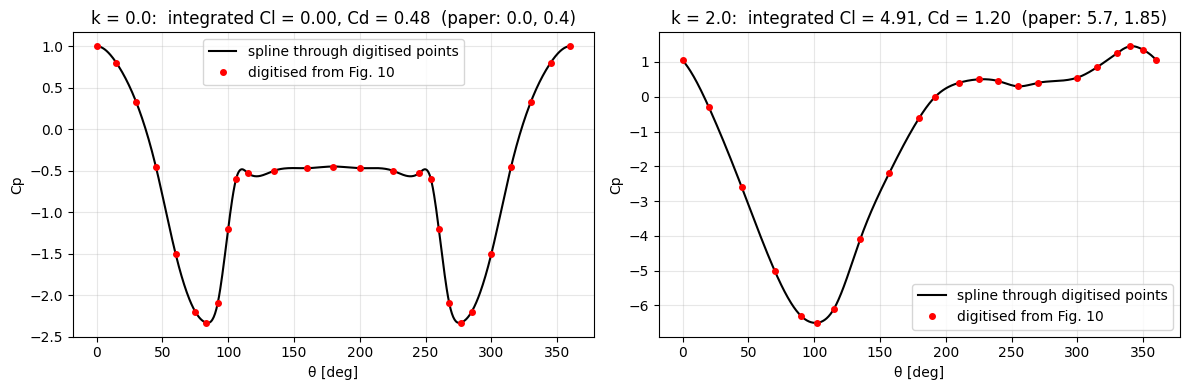

In [2]:
# (angle in degrees, Cp) read from Bordogna et al. 2019, Fig. 10, Re = 3.6e5 (red curves)
CP_TABLE = {
    0.0: [(0,1.00),(15,0.80),(30,0.33),(45,-0.45),(60,-1.50),(75,-2.20),(83,-2.33),(92,-2.10),
          (100,-1.20),(106,-0.60),(115,-0.53),(135,-0.50),(160,-0.47),(180,-0.45),(200,-0.47),
          (225,-0.50),(245,-0.53),(254,-0.60),(260,-1.20),(268,-2.10),(277,-2.33),(285,-2.20),
          (300,-1.50),(315,-0.45),(330,0.33),(345,0.80),(360,1.00)],
    2.0: [(0,1.05),(20,-0.30),(45,-2.60),(70,-5.00),(90,-6.30),(102,-6.50),(115,-6.10),(135,-4.10),
          (157,-2.20),(180,-0.60),(192,0.00),(210,0.40),(225,0.50),(240,0.45),(255,0.30),(270,0.40),
          (300,0.55),(315,0.85),(330,1.25),(340,1.45),(350,1.35),(360,1.05)],
}

# Cl and Cd reported by the paper for Re = 3.6e5 (averaged sectional values, read from Figs. 6 and 9).
PAPER_COEFFS = {0.0: {"Cl": 0.0, "Cd": 0.40}, 2.0: {"Cl": 5.7, "Cd": 1.85}}

def load_cfd_table(path):
    # Read a CFD export and return x, y (in D), u, v (divided by U) and Cp.
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    col = lambda *names: next((n for n in names if n in df.columns), None)
    x = df[col("x", "x-coordinate")].values / CFD_DIAMETER
    y = df[col("y", "y-coordinate")].values / CFD_DIAMETER
    if col("x-velocity") is not None:                 # Fluent: velocities in m/s -> divide by wind speed
        far_up = x < x.min() + 0.05 * (x.max() - x.min())
        U_inf = df.loc[far_up, "x-velocity"].mean()
        u, v = df["x-velocity"].values / U_inf, df["y-velocity"].values / U_inf
        print(f"CFD file {path}: {len(df)} nodes, wind speed from upstream nodes = {U_inf:.3f} m/s")
    else:                                             # already non-dimensional
        u = df[col("u", "u/U", "expr:u_scaled")].values
        v = df[col("v", "v/U")].values if col("v", "v/U") else np.zeros_like(u)
    cp_col = col("Cp", "cp", "expr:P_scaled", "pressure-coefficient")
    cp = df[cp_col].values if cp_col else np.full_like(u, np.nan)
    return pd.DataFrame({"x": x, "y": y, "u": u, "v": v, "Cp": cp})

def cfd_wall_cp_table(path, step_deg=5.0):
    # Wall Cp from the CFD file, as (angle in degrees, Cp) pairs every step_deg degrees.
    cfd = load_cfd_table(path)
    w = np.hypot(cfd.x, cfd.y) < R * 1.002                    # nodes on the rotor surface
    th = np.mod(np.arctan2(cfd.y[w], -cfd.x[w]), 2 * np.pi).values
    o = np.argsort(th); th, cp = th[o], cfd.Cp[w].values[o]
    grid = np.arange(0, 360, step_deg)
    cpg = np.interp(np.radians(grid), np.r_[th, th[0] + 2 * np.pi], np.r_[cp, cp[0]])
    return list(zip(grid, cpg)) + [(360.0, cpg[0])]

for k in SPIN_RATIOS:
    if CP_SOURCE.get(k) == "cfd":
        CP_TABLE[k] = cfd_wall_cp_table(CFD_FILES[k])
        print(f"k = {k}: training on the CFD wall pressure from {CFD_FILES[k]}")

def cp_spline(k):
    # Smooth periodic curve through the table points. Returns a function Cp(theta_in_radians).
    pts = np.array(CP_TABLE[k])
    return CubicSpline(np.radians(pts[:, 0]), pts[:, 1], bc_type="periodic")

def cl_cd_from_cp(theta, cp):
    # Integrate pressure around the circle (pressure part only, like the paper).
    #   Cd = 1/2 * integral of Cp*cos(theta)      (force along the wind)
    #   Cl = -1/2 * integral of Cp*sin(theta)     (force towards theta = 90 deg)
    # theta: angles in radians covering a full circle with equal spacing, endpoint excluded.
    dtheta = 2 * np.pi / len(theta)
    cd = 0.5 * np.sum(cp * np.cos(theta)) * dtheta
    cl = -0.5 * np.sum(cp * np.sin(theta)) * dtheta
    return cl, cd

theta_dense = np.linspace(0, 2*np.pi, 720, endpoint=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, k in enumerate(SPIN_RATIOS):
    cs = cp_spline(k)
    pts = np.array(CP_TABLE[k])
    ax[i].plot(np.degrees(theta_dense), cs(theta_dense), "k-", label="spline through digitised points")
    ax[i].plot(pts[:, 0], pts[:, 1], "ro", ms=4, label="digitised from Fig. 10")
    cl, cd = cl_cd_from_cp(theta_dense, cs(theta_dense))
    ax[i].set_title(f"k = {k}:  integrated Cl = {cl:.2f}, Cd = {cd:.2f}  (paper: {PAPER_COEFFS[k]['Cl']}, {PAPER_COEFFS[k]['Cd']})")
    ax[i].set_xlabel("θ [deg]"); ax[i].set_ylabel("Cp"); ax[i].grid(alpha=.3); ax[i].legend()
plt.tight_layout(); plt.show()

### Which points does the network see?
* **Training (sensor) points:** 32 equally spaced angles (0°, 11.25°, 22.5°, …).
* **Test points:** the angles exactly halfway between sensors. The network never sees these; we use them to check how well it fills the gaps.

In [3]:
def paper_angle_to_xy(theta, r=R):
    # Paper angle (radians) -> x, y. Wind along +x, lift along +y.
    return -r * np.cos(theta), r * np.sin(theta)

def xy_to_paper_angle(x, y):
    return np.mod(np.arctan2(y, -x), 2 * np.pi)

theta_train = np.arange(N_SENSORS) * 2 * np.pi / N_SENSORS
theta_test  = theta_train + np.pi / N_SENSORS
def cp_target(k, theta):
    # Cp values the network is trained against (capped at 1 if CLIP_CP_ABOVE_1 is on)
    cp = cp_spline(k)(theta)
    return np.minimum(cp, 1.0) if CLIP_CP_ABOVE_1 else cp

SENSORS = {k: {"theta_train": theta_train, "cp_train": cp_target(k, theta_train),
               "theta_test": theta_test,   "cp_test":  cp_target(k, theta_test)} for k in SPIN_RATIOS}
print("Sensors per case:", N_SENSORS, "| test points per case:", len(theta_test))
for k in SPIN_RATIOS:
    n_cut = int(np.sum(cp_spline(k)(theta_train) > 1.0))
    cl_a, cd_a = cl_cd_from_cp(theta_dense, cp_spline(k)(theta_dense))
    cl_b, cd_b = cl_cd_from_cp(theta_dense, cp_target(k, theta_dense))
    print(f"k = {k}: {n_cut} sensor values capped at Cp = 1 | Cl {cl_a:.2f} -> {cl_b:.2f}, Cd {cd_a:.2f} -> {cd_b:.2f}")

Sensors per case: 32 | test points per case: 32
k = 0.0: 0 sensor values capped at Cp = 1 | Cl 0.00 -> 0.00, Cd 0.48 -> 0.48
k = 2.0: 4 sensor values capped at Cp = 1 | Cl 4.91 -> 4.88, Cd 1.20 -> 1.11


## 3. The physics: equations the network must satisfy

Unknowns everywhere around the rotor: horizontal velocity **u**, vertical velocity **v**, pressure **p** (all non-dimensional).

**Mass conservation (continuity)**
$$ \frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0 $$

**Momentum (steady, time-averaged Navier–Stokes with an effective viscosity ν_eff = 1/Re_eff)**
$$ u\frac{\partial u}{\partial x} + v\frac{\partial u}{\partial y} = -\frac{\partial p}{\partial x} + \nu_{eff}\left(\frac{\partial^2 u}{\partial x^2}+\frac{\partial^2 u}{\partial y^2}\right) $$
$$ u\frac{\partial v}{\partial x} + v\frac{\partial v}{\partial y} = -\frac{\partial p}{\partial y} + \nu_{eff}\left(\frac{\partial^2 v}{\partial x^2}+\frac{\partial^2 v}{\partial y^2}\right) $$

**Boundary conditions**
* **On the rotor surface (r = R):** the air moves with the surface (no-slip). The surface turns with angular speed Ω = k·U/R, so
  `u = Ω·y`, `v = −Ω·x`. This is built **exactly** into the network (see the model code), so it is never violated.
* **Far away (r = R_OUT):** the wind is uniform plus the swirl caused by the lift (a vortex of strength Γ):
  `u = 1 + Γ y /(2π r²)`, `v = −Γ x /(2π r²)`, and the pressure follows Bernoulli: `p = ½(1 − u² − v²)`.
  Γ is **learned**. By the Kutta–Joukowski theorem it gives a second, independent lift estimate: **Cl = 2Γ**.
  In the narrow wake sector behind the rotor we only ask for the pressure, because the wake has not recovered yet.

**Clean incoming air:** vorticity (local swirl, ω = ∂v/∂x − ∂u/∂y) is created only at the rotor surface and is then
carried **downstream** by the wind. So the air ahead of the rotor, outside the thin wall layer, has ω = 0.
This follows from the momentum equations themselves. We add it as an explicit rule because, without it, the network can
"cheat": it puts false swirl upstream and below the rotor to match the measured pressure more easily, which creates a wide,
unphysical slow region under the rotor at k = 2.
Region used: points with x < 0 (ahead of the rotor centre) and more than 0.25 D from the surface.

**Data:** at the 32 sensor angles, `2·p(wall) = Cp_measured`.

### Loss (what training minimises)
`Loss = W_PDE·(x-momentum² + y-momentum²) + W_CONT·continuity² + W_FAR·far-field error² + W_CP·(Cp error at sensors)² + W_IRROT·(upstream vorticity)²`

## 4. The neural network

* **Inputs:** position, given as (log of distance from the centre, cos φ, sin φ, a "near-wall" signal that is 1 on the wall and
  drops to 0 within about 0.1 D). Using cos/sin makes the solution automatically repeat every 360°. The log distance and the
  near-wall signal give the network fine resolution close to the wall, where the flow changes fastest.
* **Outputs:** corrections to u, v, and the pressure p.
* **Built-in rules (exact):**

  `u = (1 − d)·u_wall + d·(u_ideal + correction)`, with `d = 1 − exp(−(r − R)/SPIN_LAYER)`

  * `d` is 0 on the wall and reaches 1 within a few hundredths of a diameter.
  * `u_wall` is the speed of the spinning surface. It only acts inside that **thin** layer.
  * `u_ideal` is the classic ideal flow around a cylinder **with the learned circulation Γ** (uniform wind + swirl of strength Γ).
    This first guess already has the right far field and the right amount of swirl for the lift, so the network only learns
    corrections (the wake, the wall layer, the exact pressure shape).
  * On the wall d = 0, so u and v are exactly the surface speed (no-slip).

> **Why this matters for the k = 2 wake.** An earlier version let the wall's swirl spread over the whole domain
> (`u_spin ∝ 1/r`). Its circulation was 2π·k·U·R ≈ 6.3 for k = 2, which is exactly the value at which ideal-flow
> theory puts the stagnation point **off** the rotor, in the air below it. That produced a large, nearly still region
> under the rotor at y ≈ −1 that a turbulent CFD solution does not have. Now the wall's influence is confined to a thin layer
> and the swirl far away is set only by the learned Γ, which is tied to the lift.

In [4]:
class FlowPINN(nn.Module):
    def __init__(self, k, hidden=96, n_layers=5, gamma_init=0.0):
        super().__init__()
        self.k = k
        self.omega = k / R                   # angular speed of the rotor (U = 1)
        re_eff_init, self.re_min, self.re_max = RE_EFF[k]
        layers, n_in = [], 4
        for _ in range(n_layers):
            layers += [nn.Linear(n_in, hidden), nn.Tanh()]
            n_in = hidden
        layers += [nn.Linear(n_in, 3)]
        self.net = nn.Sequential(*layers)
        # Learned physical numbers
        self.log_re_eff = nn.Parameter(torch.tensor(math.log(re_eff_init)))   # effective Reynolds number
        self.gamma      = nn.Parameter(torch.tensor(float(gamma_init)))      # circulation (lift swirl)

    def re_eff(self):
        return torch.exp(self.log_re_eff).clamp(self.re_min, self.re_max)

    def nu_eff(self):
        return 1.0 / self.re_eff()

    def forward(self, x, y):
        r2 = x**2 + y**2
        r = torch.sqrt(r2)
        wall_dist = r - R
        # network inputs
        rho = torch.log(r / R) / math.log(R_OUT / R)          # 0 on the wall, 1 at the outer edge
        near_wall = torch.exp(-wall_dist / 0.03)              # 1 on the wall, ~0 beyond 0.1 D
        feats = torch.cat([2 * rho - 1, x / r, y / r, near_wall], dim=1)
        out = self.net(feats)
        # (1) speed of the spinning surface (tangential, magnitude Omega*R); used only inside the thin wall layer
        u_wall = self.omega * y * (R / r)
        v_wall = -self.omega * x * (R / r)
        # (2) ideal flow around a cylinder WITH circulation gamma: uniform wind + lift swirl (clockwise)
        u_ideal = 1 - R**2 * (x**2 - y**2) / r2**2 + self.gamma * y / (2 * math.pi * r2)
        v_ideal = -2 * R**2 * x * y / r2**2 - self.gamma * x / (2 * math.pi * r2)
        # (3) blend: d = 0 on the wall (exact no-slip), d -> 1 a few SPIN_LAYER away from it
        d = 1 - torch.exp(-wall_dist / SPIN_LAYER)
        u = (1 - d) * u_wall + d * (u_ideal + out[:, 0:1])
        v = (1 - d) * v_wall + d * (v_ideal + out[:, 1:2])
        p = out[:, 2:3]
        return u, v, p


def grad(f, x):
    # derivative of f with respect to x (keeps the graph so we can differentiate again)
    return torch.autograd.grad(f, x, grad_outputs=torch.ones_like(f), create_graph=True)[0]


def pde_residuals(model, x, y, with_vorticity=False):
    # How much the flow equations are violated at points (x, y). Zero = perfectly satisfied.
    # If with_vorticity=True, also return the vorticity (local swirl) at the same points.
    u, v, p = model(x, y)
    u_x, u_y = grad(u, x), grad(u, y)
    v_x, v_y = grad(v, x), grad(v, y)
    p_x, p_y = grad(p, x), grad(p, y)
    u_xx, u_yy = grad(u_x, x), grad(u_y, y)
    v_xx, v_yy = grad(v_x, x), grad(v_y, y)
    nu = model.nu_eff()
    mom_x = u * u_x + v * u_y + p_x - nu * (u_xx + u_yy)
    mom_y = u * v_x + v * v_y + p_y - nu * (v_xx + v_yy)
    cont  = u_x + v_y
    if with_vorticity:
        return mom_x, mom_y, cont, v_x - u_y
    return mom_x, mom_y, cont

## 5. Where the equations are checked (sampling points)

In [5]:
def to_t(a):
    return torch.tensor(np.asarray(a, dtype=np.float32).reshape(-1, 1), device=device, requires_grad=True)

def sample_domain(n):
    # Random points between the wall and the outer edge:
    #   - WAKE_POINTS share in a box behind and below the rotor (x 0..4 D, y -3..1.5 D), where the wake lives,
    #   - 15 % inside the thin layer dragged by the spinning wall (within 0.15 D),
    #   - 25 % within 0.6 D of the wall,
    #   - the rest spread over the whole region (denser near the wall).
    n_wake = int(WAKE_POINTS * n); n_thin = int(0.15 * n); n_near = int(0.25 * n)
    n_all = n - n_wake - n_thin - n_near
    r = np.concatenate([R + (R_OUT - R) * np.random.rand(n_all) ** 2,
                        R + 0.6 * np.random.rand(n_near) ** 2,
                        R + 0.15 * np.random.rand(n_thin)])
    phi = 2 * np.pi * np.random.rand(len(r))
    x, y = r * np.cos(phi), r * np.sin(phi)
    xw, yw = np.empty(0), np.empty(0)
    while len(xw) < n_wake:                                   # box points, skipping those inside the rotor
        bx, by = np.random.uniform(0, 4, n_wake), np.random.uniform(-3, 1.5, n_wake)
        ok = np.hypot(bx, by) > R + 0.01
        xw, yw = np.r_[xw, bx[ok]], np.r_[yw, by[ok]]
    x, y = np.r_[x, xw[:n_wake]], np.r_[y, yw[:n_wake]]
    return to_t(x), to_t(y)

def sample_far(n):
    phi = np.linspace(0, 2 * np.pi, n, endpoint=False)
    x, y = R_OUT * np.cos(phi), R_OUT * np.sin(phi)
    in_wake = (np.cos(phi) > 0.85)          # a ~60 deg sector straight behind the rotor
    return to_t(x), to_t(y), torch.tensor(in_wake, device=device)

def far_field_target(x, y, gamma):
    # uniform wind + vortex of strength gamma (clockwise, gives lift towards +y)
    r2 = x**2 + y**2
    u = 1 + gamma * y / (2 * np.pi * r2)
    v = -gamma * x / (2 * np.pi * r2)
    p = 0.5 * (1 - u**2 - v**2)            # Bernoulli
    return u, v, p

## 6. Forces from the predicted flow

Force on the rotor per unit span = integral over the surface of (pressure + viscous stress).
* **Pressure part** — this is what the paper measured with its pressure taps (sectional Cl, Cd). This is the number to compare.
* **Viscous (friction) part** — reported for information only. Because ν_eff is a model value, not real air viscosity, treat it with care.

In [6]:
def wall_forces(model, n=720):
    theta = np.arange(n) * 2 * np.pi / n
    xw, yw = paper_angle_to_xy(theta)
    x, y = to_t(xw), to_t(yw)
    u, v, p = model(x, y)
    u_x, u_y, v_x, v_y = grad(u, x), grad(u, y), grad(v, x), grad(v, y)
    nx, ny = x / R, y / R                      # outward normal of the body (pointing into the air)
    ds = 2 * np.pi * R / n
    nu = model.nu_eff()
    # traction = -p n + nu (grad u + grad u^T) n
    fx_p = (-p * nx).sum() * ds
    fy_p = (-p * ny).sum() * ds
    fx_v = (nu * (2 * u_x * nx + (u_y + v_x) * ny)).sum() * ds
    fy_v = (nu * ((u_y + v_x) * nx + 2 * v_y * ny)).sum() * ds
    to = lambda t: 2 * t.item()                # coefficient = force / (0.5 rho U^2 D)
    cp = 2 * p.detach().cpu().numpy().ravel()
    return dict(theta=theta, cp=cp,
                Cd_pressure=to(fx_p), Cl_pressure=to(fy_p),
                Cd_friction=to(fx_v), Cl_friction=to(fy_v))

## 7. Training

In [7]:
def compute_loss(model, k, xc, yc, xf, yf, wake, xs, ys, cps):
    mom_x, mom_y, cont, vort = pde_residuals(model, xc, yc, with_vorticity=True)
    loss_pde  = (mom_x**2).mean() + (mom_y**2).mean()
    loss_cont = (cont**2).mean()

    # clean incoming air: no vorticity ahead of the rotor, outside the thin wall layer
    upstream = ((xc < 0) & (torch.sqrt(xc**2 + yc**2) > R + 0.25)).float()
    loss_irrot = (upstream * vort**2).sum() / upstream.sum().clamp(min=1.0)

    # thin layers: behind the rotor swirl is allowed, but an L1 penalty prefers it concentrated in thin sheets
    behind = ((xc >= 0) & (torch.sqrt(xc**2 + yc**2) > R + 0.25)).float()
    loss_thin = (behind * vort.abs()).sum() / behind.sum().clamp(min=1.0)

    u, v, p = model(xf, yf)
    ut, vt, pt = far_field_target(xf, yf, model.gamma)
    not_wake = (~wake).float().reshape(-1, 1)
    loss_far = (not_wake * ((u - ut)**2 + (v - vt)**2)).sum() / not_wake.sum() + ((p - pt)**2).mean()

    _, _, ps = model(xs, ys)
    loss_cp = ((2 * ps - cps)**2).mean()

    total = (W_PDE * loss_pde + W_CONT * loss_cont + W_FAR * loss_far + W_CP * loss_cp
             + W_IRROT * loss_irrot + W_THIN * loss_thin)
    parts = dict(total=total.item(), pde=loss_pde.item(), cont=loss_cont.item(),
                 far=loss_far.item(), cp=loss_cp.item(), irrot=loss_irrot.item(),
                 thin=loss_thin.item())
    return total, parts


def train_case(k):
    print(f"\n================  Training case k = {k}  ================")
    s = SENSORS[k]
    cl0, _ = cl_cd_from_cp(theta_dense, cp_spline(k)(theta_dense))
    model = FlowPINN(k, gamma_init=cl0 / 2).to(device)     # start circulation from Cl = 2*Gamma

    xs_np, ys_np = paper_angle_to_xy(s["theta_train"])
    xs, ys = to_t(xs_np), to_t(ys_np)
    cps = torch.tensor(s["cp_train"], dtype=torch.float32, device=device).reshape(-1, 1)
    xf, yf, wake = sample_far(N_FAR)

    history = []
    t0 = time.time()

    # ---- Stage 1: Adam ----
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, ADAM_ITERS // 4), gamma=0.5)
    for it in range(ADAM_ITERS):
        if it % RESAMPLE_EVERY == 0:
            xc, yc = sample_domain(N_COLLOC)
        opt.zero_grad()
        loss, parts = compute_loss(model, k, xc, yc, xf, yf, wake, xs, ys, cps)
        loss.backward()
        opt.step(); sched.step()
        if it % 200 == 0 or it == ADAM_ITERS - 1:
            parts.update(it=it, Re_eff=model.re_eff().item(), Gamma=model.gamma.item())
            history.append(parts)
        if it % 2000 == 0 or it == ADAM_ITERS - 1:
            print(f"Adam {it:6d} | loss {parts['total']:.3e} | pde {parts['pde']:.2e} | cont {parts['cont']:.2e} "
                  f"| far {parts['far']:.2e} | Cp {parts['cp']:.2e} | irrot {parts['irrot']:.2e} | Re_eff {model.re_eff().item():7.1f} "
                  f"| Gamma {model.gamma.item():.3f} | {time.time()-t0:5.0f}s")

    # ---- Stage 2: L-BFGS (fine polishing on a fixed set of points) ----
    if LBFGS_ITERS > 0:
        xc, yc = sample_domain(N_COLLOC)
        lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=LBFGS_ITERS, history_size=50,
                                  tolerance_grad=1e-9, tolerance_change=1e-12, line_search_fn="strong_wolfe")
        counter = [0]
        def closure():
            lbfgs.zero_grad()
            loss, parts = compute_loss(model, k, xc, yc, xf, yf, wake, xs, ys, cps)
            loss.backward()
            counter[0] += 1
            if counter[0] % 200 == 0:
                parts.update(it=ADAM_ITERS + counter[0], Re_eff=model.re_eff().item(), Gamma=model.gamma.item())
                history.append(parts)
                print(f"LBFGS {counter[0]:5d} | loss {parts['total']:.3e} | Cp {parts['cp']:.2e} | {time.time()-t0:5.0f}s")
            return loss
        lbfgs.step(closure)

    print(f"Finished k = {k} in {time.time()-t0:.0f} s | Re_eff = {model.re_eff().item():.1f} | Gamma = {model.gamma.item():.3f}")
    torch.save(model.state_dict(), f"{OUT_DIR}/pinn_k{k}.pt")
    return model, pd.DataFrame(history)

In [8]:
MODELS, HISTORY = {}, {}
for k in SPIN_RATIOS:
    MODELS[k], HISTORY[k] = train_case(k)


================  Training case k = 0.0  ================
Adam      0 | loss 2.557e+01 | pde 2.10e+00 | cont 5.65e-01 | far 2.49e-02 | Cp 1.14e+00 | irrot 7.36e-04 | Re_eff   200.2 | Gamma 0.001 |    12s
Adam   2000 | loss 2.237e-01 | pde 1.24e-01 | cont 6.40e-02 | far 1.67e-04 | Cp 1.65e-03 | irrot 5.43e-04 | Re_eff   212.7 | Gamma -0.107 |   198s
Adam   4000 | loss 1.840e-01 | pde 1.03e-01 | cont 5.89e-02 | far 1.01e-04 | Cp 1.03e-03 | irrot 2.89e-04 | Re_eff   261.3 | Gamma -0.072 |   379s
Adam   6000 | loss 1.546e-01 | pde 9.65e-02 | cont 4.29e-02 | far 5.63e-05 | Cp 7.06e-04 | irrot 1.91e-04 | Re_eff   368.3 | Gamma -0.051 |   559s
Adam   8000 | loss 2.175e-01 | pde 1.70e-01 | cont 3.85e-02 | far 7.08e-05 | Cp 3.81e-04 | irrot 1.55e-04 | Re_eff   592.7 | Gamma -0.046 |   747s
Adam  10000 | loss 2.845e-01 | pde 1.80e-01 | cont 6.11e-02 | far 6.88e-04 | Cp 1.95e-03 | irrot 5.56e-04 | Re_eff   871.8 | Gamma -0.040 |   935s
Adam  12000 | loss 1.902e-01 | pde 1.21e-01 | cont 6.31e-02 

## 8. Training history (did it converge?)

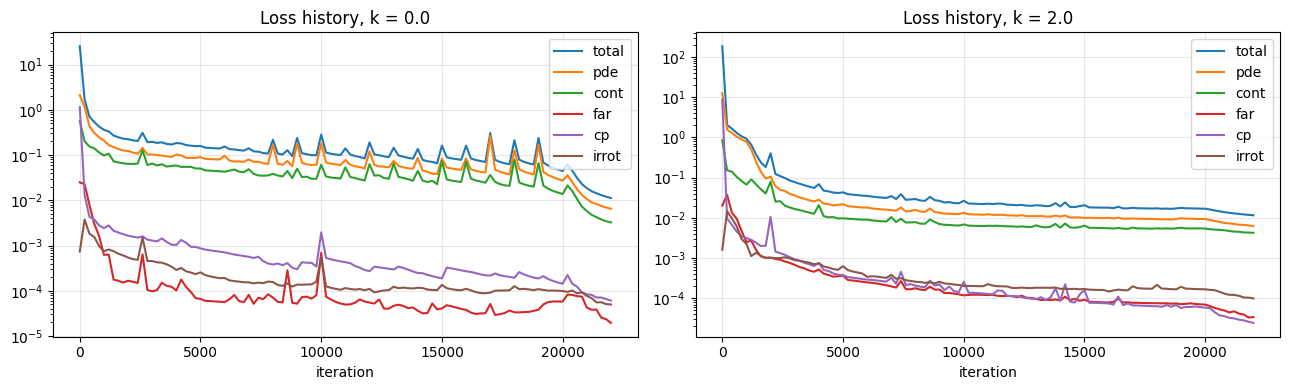

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, k in enumerate(SPIN_RATIOS):
    h = HISTORY[k]
    for col in ["total", "pde", "cont", "far", "cp", "irrot"]:
        ax[i].semilogy(h["it"], h[col], label=col)
    ax[i].set_title(f"Loss history, k = {k}"); ax[i].set_xlabel("iteration"); ax[i].legend(); ax[i].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/loss_history.png", dpi=150); plt.show()

## 9. Result 1 — Cp around the rotor

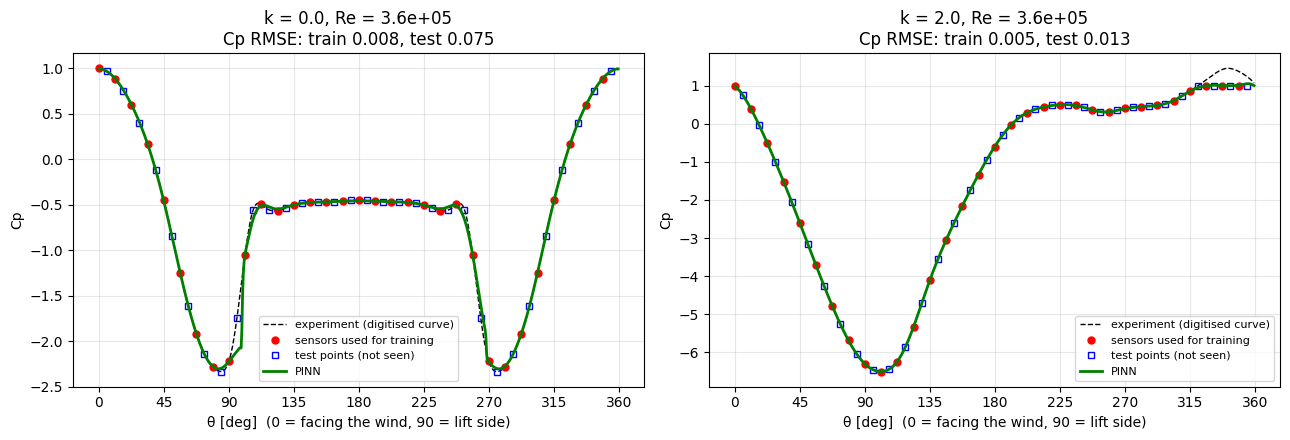

In [10]:
RESULTS = {}
for k in SPIN_RATIOS:
    RESULTS[k] = wall_forces(MODELS[k])

def predict_cp(model, theta):
    xw, yw = paper_angle_to_xy(theta)
    with torch.no_grad():
        _, _, p = model(torch.tensor(xw, dtype=torch.float32, device=device).reshape(-1, 1),
                        torch.tensor(yw, dtype=torch.float32, device=device).reshape(-1, 1))
    return 2 * p.cpu().numpy().ravel()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for i, k in enumerate(SPIN_RATIOS):
    s, res = SENSORS[k], RESULTS[k]
    ax[i].plot(np.degrees(theta_dense), cp_spline(k)(theta_dense), "k--", lw=1, label="experiment (digitised curve)")
    ax[i].plot(np.degrees(s["theta_train"]), s["cp_train"], "ro", ms=5, label="sensors used for training")
    ax[i].plot(np.degrees(s["theta_test"]), s["cp_test"], "bs", ms=4, mfc="none", label="test points (not seen)")
    ax[i].plot(np.degrees(res["theta"]), res["cp"], "g-", lw=2, label="PINN")
    rmse_tr = np.sqrt(np.mean((predict_cp(MODELS[k], s["theta_train"]) - s["cp_train"])**2))
    rmse_te = np.sqrt(np.mean((predict_cp(MODELS[k], s["theta_test"]) - s["cp_test"])**2))
    ax[i].set_title(f"k = {k}, Re = {RE_EXP:.1e}\nCp RMSE: train {rmse_tr:.3f}, test {rmse_te:.3f}")
    ax[i].set_xlabel("θ [deg]  (0 = facing the wind, 90 = lift side)"); ax[i].set_ylabel("Cp")
    ax[i].set_xticks(range(0, 361, 45)); ax[i].grid(alpha=.3); ax[i].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cp_comparison.png", dpi=150); plt.show()

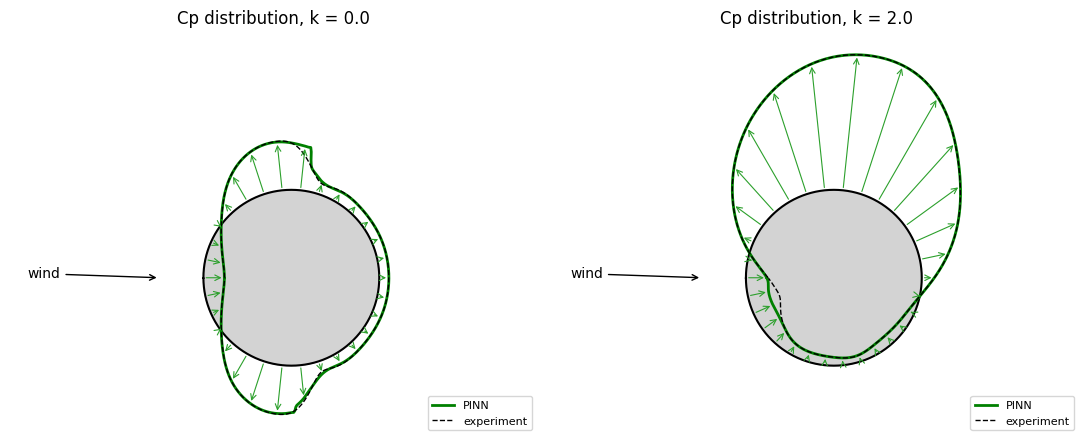

In [11]:
# Polar view like the paper: arrows show suction (pointing out) and pressure (pointing in).
fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
for i, k in enumerate(SPIN_RATIOS):
    res = RESULTS[k]
    th, cp = res["theta"], res["cp"]
    xw, yw = paper_angle_to_xy(th)
    scale = 0.12
    rr = R + scale * (-cp)                    # suction drawn outwards
    ax[i].fill(xw, yw, color="lightgray", zorder=0)
    ax[i].plot(xw, yw, "k-")
    ax[i].plot(-rr * np.cos(th), rr * np.sin(th), "g-", lw=2, label="PINN")
    cpe = cp_spline(k)(th); re_ = R + scale * (-cpe)
    ax[i].plot(-re_ * np.cos(th), re_ * np.sin(th), "k--", lw=1, label="experiment")
    for j in range(0, len(th), 24):
        ax[i].annotate("", xy=(-rr[j]*np.cos(th[j]), rr[j]*np.sin(th[j])), xytext=(xw[j], yw[j]),
                       arrowprops=dict(arrowstyle="->", color="tab:green", lw=0.8))
    ax[i].annotate("wind", xy=(-0.75, 0), xytext=(-1.5, 0), arrowprops=dict(arrowstyle="->"))
    ax[i].set_aspect("equal"); ax[i].set_title(f"Cp distribution, k = {k}"); ax[i].legend(loc="lower right", fontsize=8)
    ax[i].set_xlim(-1.6, 1.4); ax[i].set_ylim(-0.9, 1.4); ax[i].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cp_polar.png", dpi=150); plt.show()

## 10. Result 2 — Lift and drag coefficients

Columns:
* **Paper** — sectional Cl, Cd reported in Figs. 6/9 (Re = 3.6·10⁵, read by eye).
* **Cp curve integral** — integral of the digitised Fig. 10 curve (the "best" a perfect pressure fit can give).
* **PINN (pressure)** — integral of the PINN wall pressure. Compare this with the two above.
* **PINN (Kutta–Joukowski)** — Cl = 2Γ from the learned far-field swirl (an independent check of lift).
* **PINN friction** — viscous part (model value only).

In [12]:
rows = []
for k in SPIN_RATIOS:
    res, m = RESULTS[k], MODELS[k]
    cl_int, cd_int = cl_cd_from_cp(theta_dense, cp_spline(k)(theta_dense))
    rows.append({"k": k,
                 "Cl paper": PAPER_COEFFS[k]["Cl"], "Cl Cp-curve integral": round(cl_int, 3),
                 "Cl PINN (pressure)": round(res["Cl_pressure"], 3),
                 "Cl PINN (Kutta-Joukowski = 2Γ)": round(2 * m.gamma.item(), 3),
                 "Cd paper": PAPER_COEFFS[k]["Cd"], "Cd Cp-curve integral": round(cd_int, 3),
                 "Cd PINN (pressure)": round(res["Cd_pressure"], 3),
                 "Cd PINN friction (info)": round(res["Cd_friction"], 4),
                 "Re_eff learned": round(m.re_eff().item(), 1)})
coeff_table = pd.DataFrame(rows).set_index("k")
coeff_table.to_csv(f"{OUT_DIR}/coefficients.csv")
display(coeff_table.T)

k,0.0,2.0
Cl paper,0.0000,5.7000
Cl Cp-curve integral,0.0000,4.9110
Cl PINN (pressure),0.0340,4.8800
Cl PINN (Kutta-Joukowski = 2Γ),0.0120,2.9590
Cd paper,0.4000,1.8500
Cd Cp-curve integral,0.4760,1.2000
Cd PINN (pressure),0.4810,1.1080
Cd PINN friction (info),0.0707,0.1639
Re_eff learned,4013.8000,709.5000


## 11. Result 3 — Flow field around the rotor

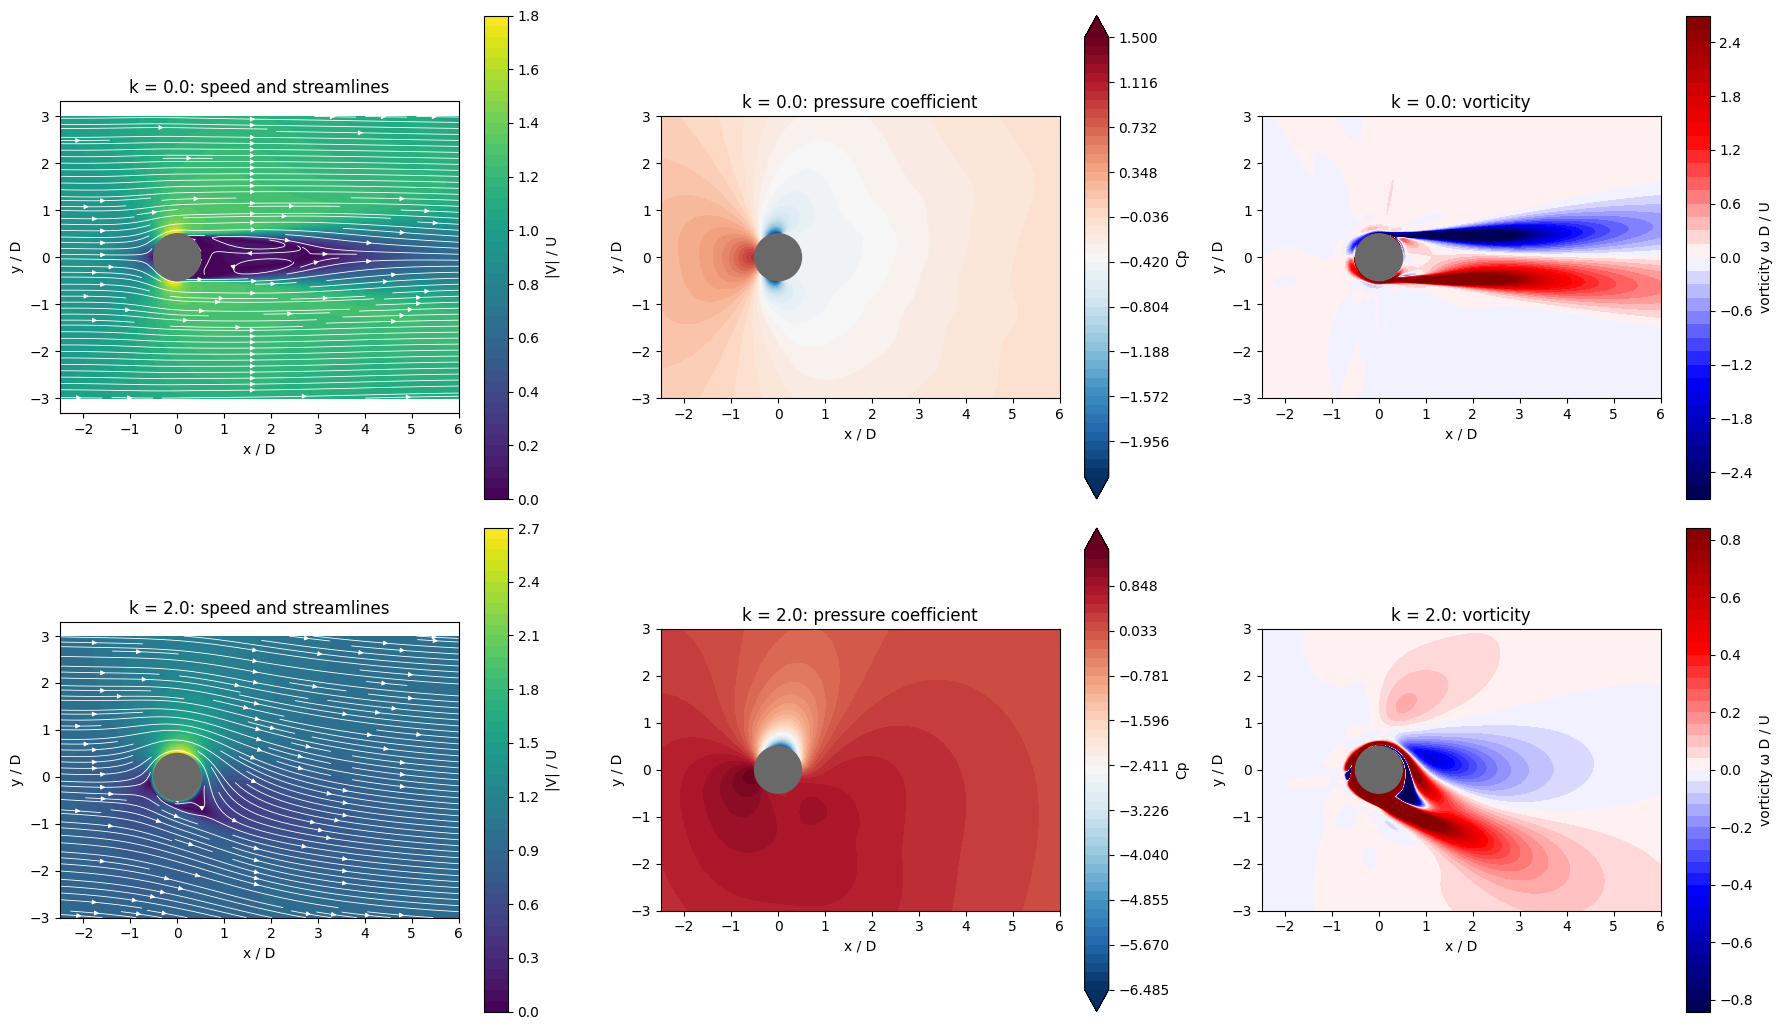

In [13]:
def field_on_grid(model, nx=420, ny=300, xlim=(-2.5, 6.0), ylim=(-3.0, 3.0), batch=20000):
    xs = np.linspace(*xlim, nx); ys = np.linspace(*ylim, ny)
    X, Y = np.meshgrid(xs, ys)
    xf, yf = X.ravel(), Y.ravel()
    inside = xf**2 + yf**2 < R**2
    xf_eval = np.where(inside, 0.0, xf); yf_eval = np.where(inside, R + 0.01, yf)   # dummy points inside body
    U, V, P, W = (np.zeros_like(xf) for _ in range(4))
    for i in range(0, len(xf), batch):
        x = to_t(xf_eval[i:i+batch]); y = to_t(yf_eval[i:i+batch])
        u, v, p = model(x, y)
        w = grad(v, x) - grad(u, y)            # vorticity
        U[i:i+batch] = u.detach().cpu().numpy().ravel()
        V[i:i+batch] = v.detach().cpu().numpy().ravel()
        P[i:i+batch] = p.detach().cpu().numpy().ravel()
        W[i:i+batch] = w.detach().cpu().numpy().ravel()
    mask = inside.reshape(X.shape)
    f = lambda a: np.ma.array(a.reshape(X.shape), mask=mask)
    return X, Y, f(U), f(V), f(2 * P), f(W)

FIELDS = {k: field_on_grid(MODELS[k]) for k in SPIN_RATIOS}

def draw_body(ax):
    ax.add_patch(plt.Circle((0, 0), R, color="dimgray", zorder=5))
    ax.set_aspect("equal"); ax.set_xlabel("x / D"); ax.set_ylabel("y / D")

fig, axes = plt.subplots(len(SPIN_RATIOS), 3, figsize=(18, 5.2 * len(SPIN_RATIOS)))
for i, k in enumerate(SPIN_RATIOS):
    X, Y, U, V, CP, W = FIELDS[k]
    speed = np.sqrt(U**2 + V**2)
    # (a) speed + streamlines
    ax = axes[i, 0]
    c = ax.contourf(X, Y, speed, levels=50, cmap="viridis")
    ax.streamplot(X, Y, U.filled(0), V.filled(0), color="white", density=1.6, linewidth=0.6, arrowsize=0.7)
    plt.colorbar(c, ax=ax, label="|V| / U"); draw_body(ax); ax.set_title(f"k = {k}: speed and streamlines")
    # (b) pressure
    ax = axes[i, 1]
    c = ax.contourf(X, Y, CP, levels=np.linspace(max(CP.min(), -7), 1.5, 50), cmap="RdBu_r", extend="both")
    plt.colorbar(c, ax=ax, label="Cp"); draw_body(ax); ax.set_title(f"k = {k}: pressure coefficient")
    # (c) vorticity
    ax = axes[i, 2]
    wl = np.percentile(np.abs(W.compressed()), 98)
    c = ax.contourf(X, Y, np.clip(W, -wl, wl), levels=50, cmap="seismic")
    plt.colorbar(c, ax=ax, label="vorticity ω D / U"); draw_body(ax); ax.set_title(f"k = {k}: vorticity")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/flow_fields.png", dpi=150); plt.show()

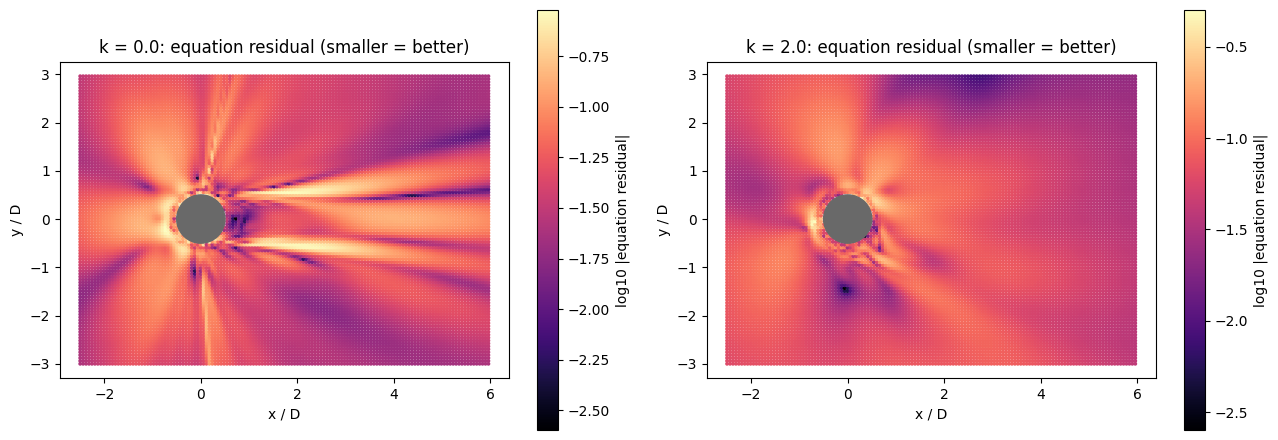

In [14]:
# Where are the equations least satisfied? (a check of the physics, not of the data)
fig, axes = plt.subplots(1, len(SPIN_RATIOS), figsize=(13, 4.5))
for i, k in enumerate(SPIN_RATIOS):
    X, Y, *_ = FIELDS[k]
    xs, ys = X[::3, ::3].ravel(), Y[::3, ::3].ravel()
    keep = xs**2 + ys**2 > R**2
    x, y = to_t(xs[keep]), to_t(ys[keep])
    mx, my, c = pde_residuals(MODELS[k], x, y)
    res = torch.sqrt(mx**2 + my**2 + c**2).detach().cpu().numpy().ravel()
    sc = axes[i].scatter(xs[keep], ys[keep], c=np.log10(res + 1e-8), s=3, cmap="magma")
    plt.colorbar(sc, ax=axes[i], label="log10 |equation residual|")
    draw_body(axes[i]); axes[i].set_title(f"k = {k}: equation residual (smaller = better)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pde_residual.png", dpi=150); plt.show()

## 11b. Comparison with your CFD

Upload your CFD export to Colab (left panel → Files → upload) and set its name in `CFD_FILES` (Section 1).
The loader understands a Fluent export with columns `x-coordinate, y-coordinate, x-velocity, y-velocity` and `expr:P_scaled` (= Cp),
or a simple file with columns `x, y, u, v, Cp`. Lengths are divided by `CFD_DIAMETER`, and velocities are divided by the wind speed
(taken from the far-upstream nodes) when they are in m/s.

This section draws:
1. **u/U and Cp maps**, CFD vs PINN, plus their difference. The window is −3…3 D and the colour range matches your CFD figure.
2. **Wall pressure**: CFD vs experiment vs PINN, with Cl and Cd from each.
3. **Profiles**: u/U across the wake at 1 D and 2 D behind the rotor, and straight below it.
4. **Error table** by region. It is area-weighted: the CFD is put on a regular grid first, so the fine mesh near the wall does
   not dominate the averages.

**How to read it.** The PINN reproduces whatever wall pressure it is trained on. If the CFD wall pressure differs from the
experiment, the flow fields will also differ, and that is a difference between CFD and experiment, not a PINN error.
To test the PINN method alone, set `CP_SOURCE[2.0] = "cfd"` in Section 1 and rerun: the PINN then learns from 32 CFD wall
pressures and should rebuild the CFD flow field.

k = 0.0: no CFD file found (None); showing the PINN only.


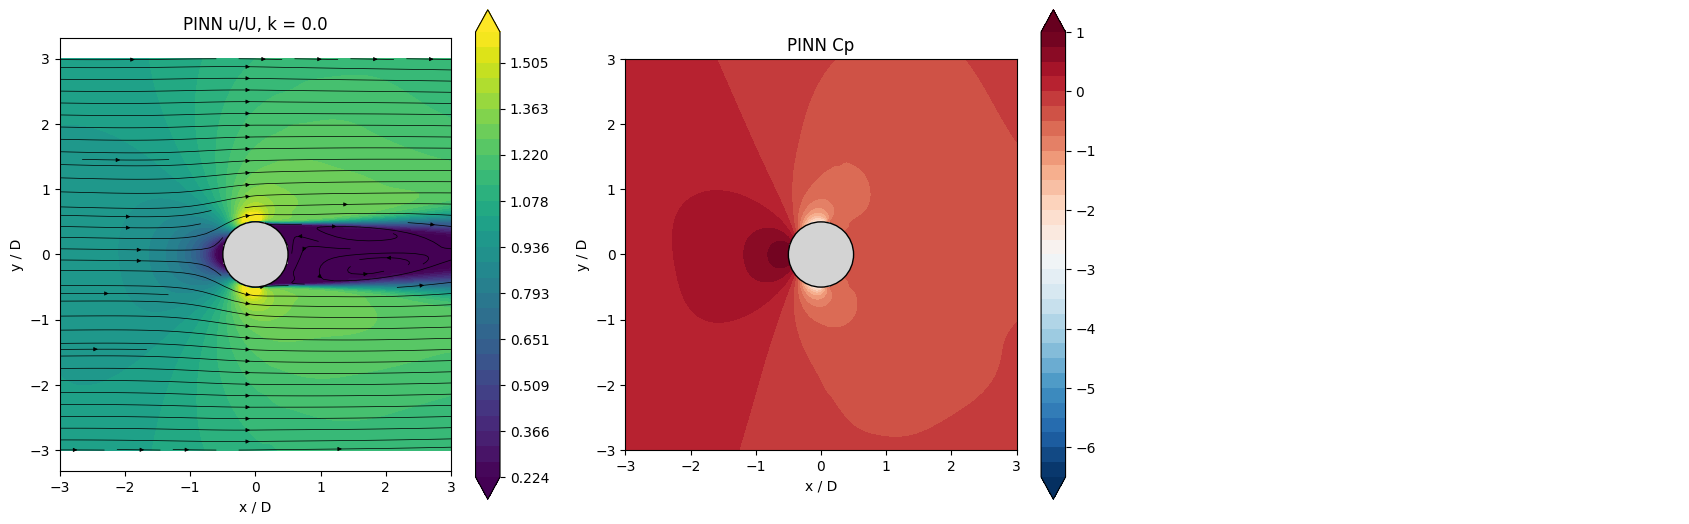

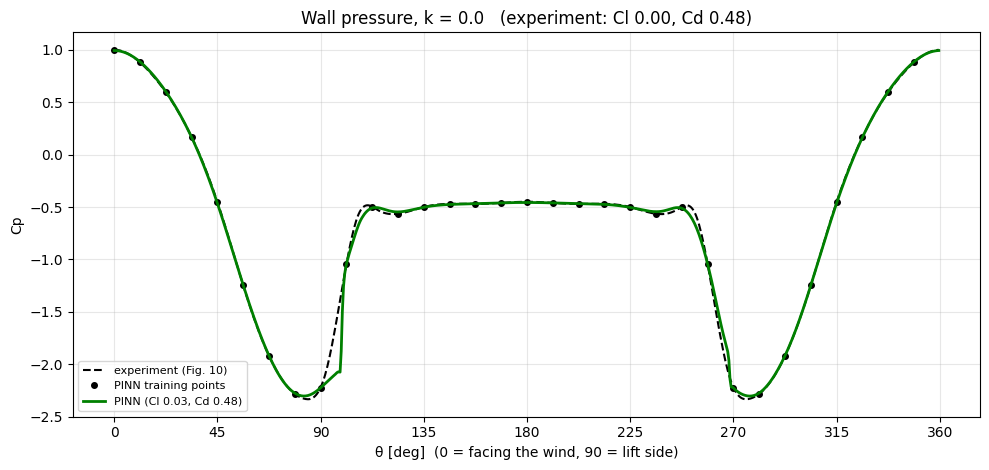

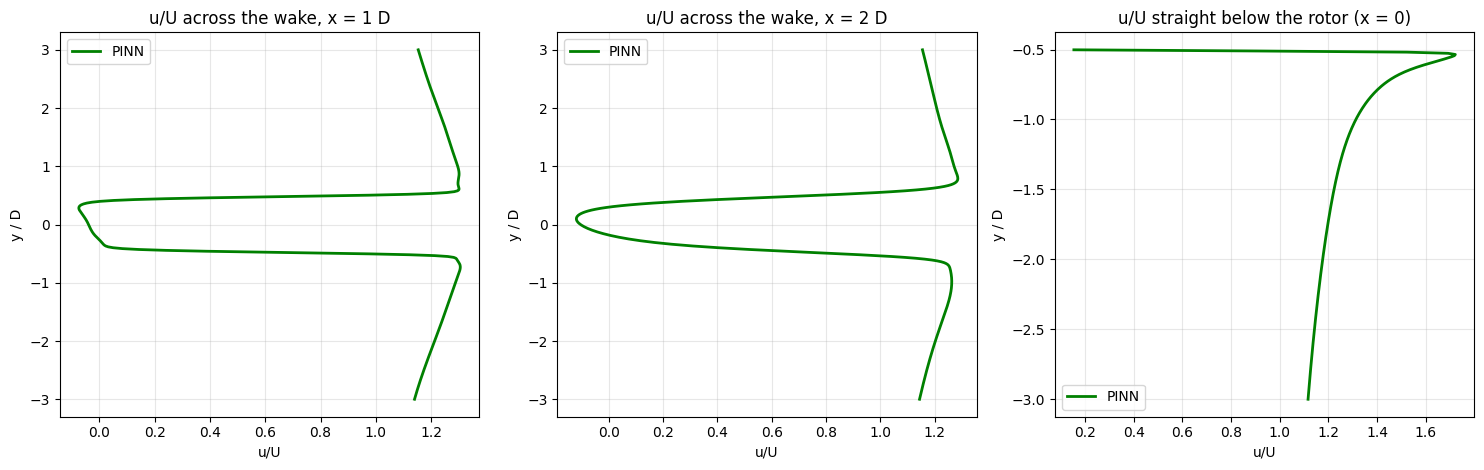

k = 2.0: no CFD file found (u_p_CFD_new.csv); showing the PINN only.


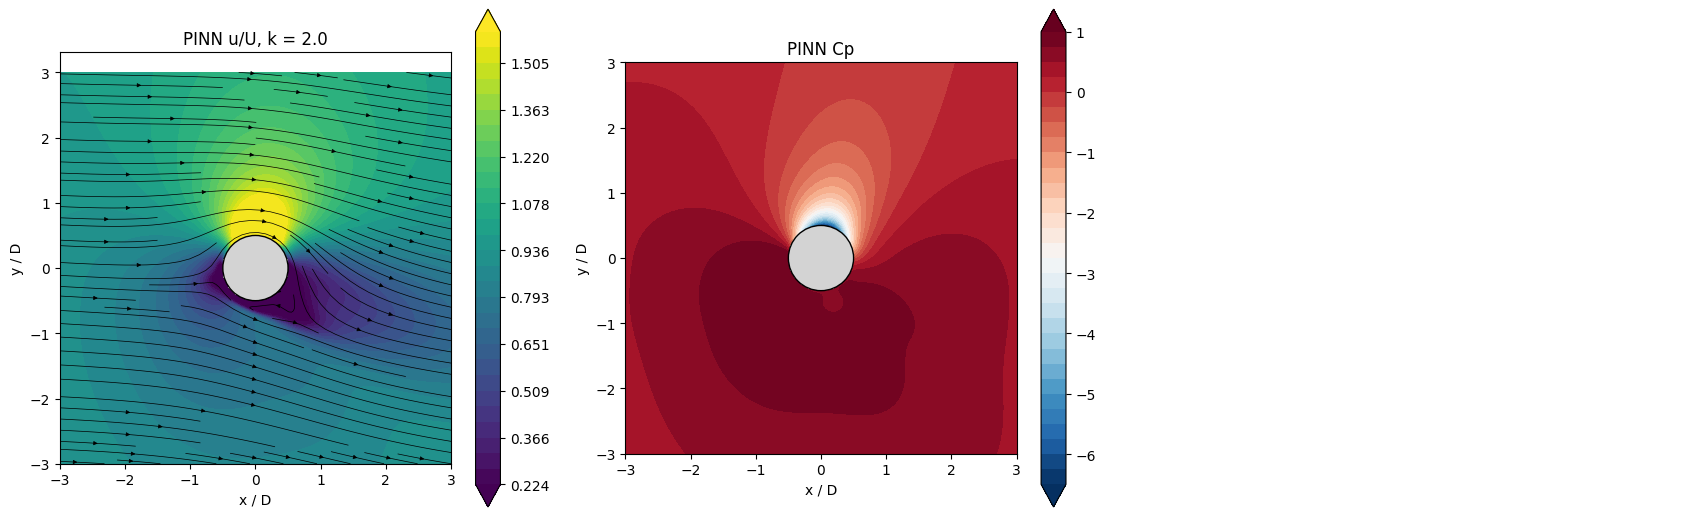

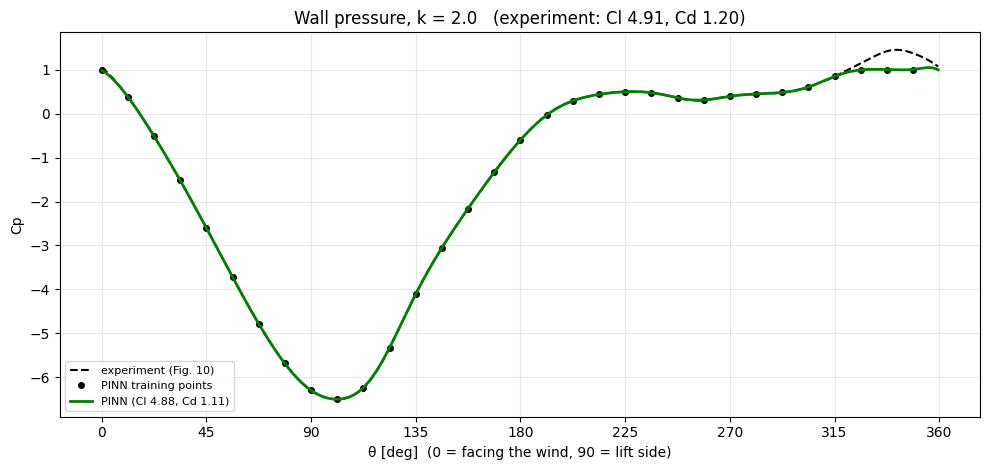

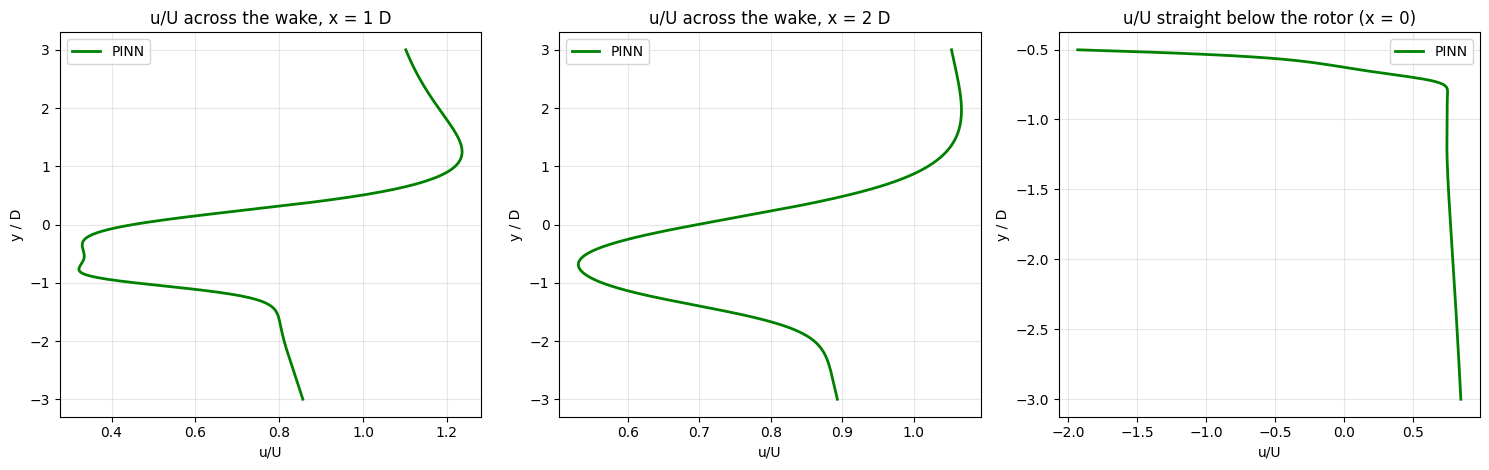

In [15]:
from scipy.interpolate import griddata

def pinn_at(model, x, y):
    with torch.no_grad():
        u, v, p = model(torch.tensor(x, dtype=torch.float32, device=device).reshape(-1, 1),
                        torch.tensor(y, dtype=torch.float32, device=device).reshape(-1, 1))
    return u.cpu().numpy().ravel(), v.cpu().numpy().ravel(), 2 * p.cpu().numpy().ravel()

def draw_body_light(ax):
    ax.add_patch(plt.Circle((0, 0), R, color="lightgray", ec="k", zorder=5))
    ax.set_aspect("equal"); ax.set_xlabel("x / D"); ax.set_ylabel("y / D")

LEVELS_U  = np.linspace(0.224, 1.6, 30)       # same range as the CFD figure
LEVELS_CP = np.linspace(-6.5, 1.0, 31)
CFD_ERRORS = {}

for k in SPIN_RATIOS:
    m = MODELS[k]
    path = CFD_FILES.get(k)
    have_cfd = path is not None and os.path.exists(path)
    if not have_cfd:
        print(f"k = {k}: no CFD file found ({path}); showing the PINN only.")

    # ---- PINN on a regular grid ----
    n = 241
    g = np.linspace(-3, 3, n); X, Y = np.meshgrid(g, g)
    body = X**2 + Y**2 < R**2
    xe = np.where(body, 0, X).ravel(); ye = np.where(body, R + 0.01, Y).ravel()
    Up, Vp, CPp = (np.ma.array(a.reshape(X.shape), mask=body) for a in pinn_at(m, xe, ye))

    if have_cfd:
        cfd = load_cfd_table(path)
        near = (np.abs(cfd.x) < 3.5) & (np.abs(cfd.y) < 3.5)
        G = lambda c: np.ma.masked_invalid(np.ma.array(
                griddata((cfd.x[near], cfd.y[near]), cfd[c][near], (X, Y), method="linear"), mask=body))
        Uc, Vc, CPc = G("u"), G("v"), G("Cp")

    # ---- 1. maps ----
    nrow = 2 if have_cfd else 1
    fig, axs = plt.subplots(nrow, 3, figsize=(17, 5.3 * nrow), squeeze=False)
    panels = [(Up, Vp, "PINN u/U")] + ([(Uc, Vc, "CFD u/U")] if have_cfd else [])
    for j, (F, Vv, t) in enumerate(panels):
        ax = axs[0, j]
        c = ax.contourf(X, Y, np.clip(F, LEVELS_U[0], LEVELS_U[-1]), levels=LEVELS_U, cmap="viridis", extend="both")
        ax.streamplot(X, Y, F.filled(0), Vv.filled(0), color="k", density=1.2, linewidth=0.5, arrowsize=0.6)
        plt.colorbar(c, ax=ax); draw_body_light(ax); ax.set_title(f"{t}, k = {k}")
    if have_cfd:
        ax = axs[0, 2]
        c = ax.contourf(X, Y, np.clip(Up - Uc, -0.8, 0.8), levels=np.linspace(-0.8, 0.8, 33), cmap="RdBu_r", extend="both")
        plt.colorbar(c, ax=ax); draw_body_light(ax); ax.set_title("PINN − CFD (u/U)\nred = PINN faster, blue = PINN slower")
        for j, (F, t) in enumerate([(CPp, "PINN Cp"), (CPc, "CFD Cp")]):
            ax = axs[1, j]
            c = ax.contourf(X, Y, np.clip(F, LEVELS_CP[0], LEVELS_CP[-1]), levels=LEVELS_CP, cmap="RdBu_r", extend="both")
            plt.colorbar(c, ax=ax); draw_body_light(ax); ax.set_title(t)
        ax = axs[1, 2]
        c = ax.contourf(X, Y, np.clip(CPp - CPc, -1, 1), levels=np.linspace(-1, 1, 33), cmap="RdBu_r", extend="both")
        plt.colorbar(c, ax=ax); draw_body_light(ax); ax.set_title("PINN − CFD (Cp)")
    else:
        ax = axs[0, 1]
        c = ax.contourf(X, Y, np.clip(CPp, LEVELS_CP[0], LEVELS_CP[-1]), levels=LEVELS_CP, cmap="RdBu_r", extend="both")
        plt.colorbar(c, ax=ax); draw_body_light(ax); ax.set_title("PINN Cp")
        axs[0, 2].axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cfd_compare_fields_k{k}.png", dpi=140); plt.show()

    # ---- 2. wall pressure ----
    res = RESULTS[k]
    cl_e, cd_e = cl_cd_from_cp(theta_dense, cp_spline(k)(theta_dense)) if CP_SOURCE[k] == "experiment" else (np.nan, np.nan)
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.plot(np.degrees(theta_dense), cp_spline(k)(theta_dense), "k--",
            label=f"{'experiment (Fig. 10)' if CP_SOURCE[k] == 'experiment' else 'training curve (from CFD)'}")
    ax.plot(np.degrees(SENSORS[k]["theta_train"]), SENSORS[k]["cp_train"], "ko", ms=4, label="PINN training points")
    if have_cfd:
        w = np.hypot(cfd.x, cfd.y) < R * 1.002
        th = np.mod(np.arctan2(cfd.y[w], -cfd.x[w]), 2 * np.pi).values; o = np.argsort(th)
        th, cpw = th[o], cfd.Cp[w].values[o]
        th_e, cp_e = np.r_[th, th[0] + 2 * np.pi], np.r_[cpw, cpw[0]]
        cd_c = 0.5 * np.trapezoid(cp_e * np.cos(th_e), th_e); cl_c = -0.5 * np.trapezoid(cp_e * np.sin(th_e), th_e)
        ax.plot(np.degrees(th), cpw, "b-", lw=2, label=f"CFD (Cl {cl_c:.2f}, Cd {cd_c:.2f})")
    ax.plot(np.degrees(res["theta"]), res["cp"], "g-", lw=2,
            label=f"PINN (Cl {res['Cl_pressure']:.2f}, Cd {res['Cd_pressure']:.2f})")
    ax.set_xticks(range(0, 361, 45)); ax.set_xlabel("θ [deg]  (0 = facing the wind, 90 = lift side)"); ax.set_ylabel("Cp")
    ax.set_title(f"Wall pressure, k = {k}" + (f"   (experiment: Cl {cl_e:.2f}, Cd {cd_e:.2f})" if not np.isnan(cl_e) else ""))
    ax.grid(alpha=.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cfd_compare_wallcp_k{k}.png", dpi=140); plt.show()

    # ---- 3. profiles ----
    ys = np.linspace(-3, 3, 400); yb = np.linspace(-R - 0.002, -3, 300)
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
    for ax, (xl, yl, title) in zip(axs, [(np.full_like(ys, 1.0), ys, "u/U across the wake, x = 1 D"),
                                         (np.full_like(ys, 2.0), ys, "u/U across the wake, x = 2 D"),
                                         (np.zeros_like(yb), yb, "u/U straight below the rotor (x = 0)")]):
        ax.plot(pinn_at(m, xl, yl)[0], yl, "g-", lw=2, label="PINN")
        if have_cfd:
            ax.plot(griddata((cfd.x[near], cfd.y[near]), cfd.u[near], (xl, yl), method="linear"), yl, "b-", lw=2, label="CFD")
        ax.set_title(title); ax.set_xlabel("u/U"); ax.set_ylabel("y / D"); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/cfd_compare_profiles_k{k}.png", dpi=140); plt.show()

    # ---- 4. area-weighted errors ----
    if have_cfd:
        regions = {"whole window": np.ones_like(X, bool), "upstream (x < -0.75)": X < -0.75,
                   "above rotor (y > 0.75)": Y > 0.75, "below rotor (|x|<1, y < -0.75)": (np.abs(X) < 1) & (Y < -0.75),
                   "wake (x > 0.75)": X > 0.75}
        rows = []
        for name, r_ in regions.items():
            mm = r_ & ~body & ~np.ma.getmaskarray(Uc) & ~np.ma.getmaskarray(CPc) & (np.hypot(X, Y) > R + 0.02)
            rows.append({"region": name,
                         "u/U RMSE": np.sqrt(np.mean((Up[mm] - Uc[mm])**2)),
                         "v/U RMSE": np.sqrt(np.mean((Vp[mm] - Vc[mm])**2)),
                         "Cp RMSE":  np.sqrt(np.mean((CPp[mm] - CPc[mm])**2)),
                         "mean u/U CFD": Uc[mm].mean(), "mean u/U PINN": Up[mm].mean()})
        CFD_ERRORS[k] = pd.DataFrame(rows).set_index("region").round(3)
        CFD_ERRORS[k].to_csv(f"{OUT_DIR}/cfd_compare_errors_k{k}.csv")
        print(f"\nk = {k}: PINN vs CFD, area-weighted errors (window -3..3 D)")
        display(CFD_ERRORS[k])

## 12. Save everything and download

In [16]:
for k in SPIN_RATIOS:
    res = RESULTS[k]
    pd.DataFrame({"theta_deg": np.degrees(res["theta"]), "Cp_PINN": res["cp"],
                  "Cp_experiment_digitised": cp_spline(k)(res["theta"])}).to_csv(f"{OUT_DIR}/cp_k{k}.csv", index=False)
    X, Y, U, V, CP, W = FIELDS[k]
    pd.DataFrame({"x": X.ravel(), "y": Y.ravel(), "u": U.filled(np.nan).ravel(), "v": V.filled(np.nan).ravel(),
                  "Cp": CP.filled(np.nan).ravel(), "vorticity": W.filled(np.nan).ravel()}
                 ).to_csv(f"{OUT_DIR}/field_k{k}.csv", index=False)
    HISTORY[k].to_csv(f"{OUT_DIR}/history_k{k}.csv", index=False)

zip_name = "flettner_pinn_results.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for f in os.listdir(OUT_DIR):
        z.write(os.path.join(OUT_DIR, f))
print("Saved:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download(zip_name)
except ImportError:
    print("Not in Colab: results are in", zip_name)

Saved: ['cfd_compare_fields_k0.0.png', 'cfd_compare_fields_k2.0.png', 'cfd_compare_profiles_k0.0.png', 'cfd_compare_profiles_k2.0.png', 'cfd_compare_wallcp_k0.0.png', 'cfd_compare_wallcp_k2.0.png', 'coefficients.csv', 'cp_comparison.png', 'cp_k0.0.csv', 'cp_k2.0.csv', 'cp_polar.png', 'field_k0.0.csv', 'field_k2.0.csv', 'flow_fields.png', 'history_k0.0.csv', 'history_k2.0.csv', 'loss_history.png', 'pde_residual.png', 'pinn_k0.0.pt', 'pinn_k2.0.pt']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Limits and how to improve

* **Better data → better result.** Swap the digitised tables for the real tap data (or several Re curves) in Section 2.
* **If Cp fits but Cl/Cd differ from the paper's Figs. 5–9:** that gap is already inside the Fig. 10 curves (see the
  "Cp-curve integral" column). The PINN cannot do better than the data it is given.
* **If the k = 0 wake looks too short or too long:** the steady model is averaging an unsteady flow. Try changing `R_OUT`,
  the wake-sector width in `sample_far`, or let viscosity vary in space (add a 4th network output for an eddy viscosity ν_t(x, y) ≥ 0).
* **k = 2: the air below the rotor is slower than in a typical CFD.** Part of this comes from the measured data, not the model.
  The paper's Cp on the lower side (about +0.3 to +0.5 at θ = 210–300°) means slow air next to the wall there. Ideal-flow theory
  with the measured lift would give Cp ≈ −0.6 at the bottom of the rotor instead. To check which one your CFD agrees with, plot your CFD's
  wall Cp against `CP_TABLE[2.0]`. If they differ on the lower side, the PINN follows the experiment and the CFD does not.
  If you trust the CFD there, train the PINN with fewer sensors on the lower side or with your CFD wall Cp.
* **What the comparison with the Delft Rotor CFD (`u_p_CFD_new.csv`, k = 2) showed** (short 3,000-step CPU test runs):
  * The CFD and the experiment disagree on the wall pressure: CFD Cl 5.15, Cd 0.18; experiment (Fig. 10) Cl 4.91, Cd 1.20.
    The experiment's suction reaches further around the back (Cp returns to 0 at about 190° vs 165°), hence its much higher drag.
  * Trained on the experiment, the PINN matches the experiment, so its wake is wider than the CFD's.
  * Trained on 32 CFD wall pressures (`CP_SOURCE[2.0] = "cfd"`), the PINN matches the CFD's Cl and Cd exactly and its flow
    above and ahead of the rotor (u/U error ≈ 0.02–0.05). A slow region below and behind the rotor remains (u/U error ≈ 0.29),
    where the network holds too much spread-out vorticity. `W_THIN = 0.5` reduces it (0.19) but weakens the thin wake wedge
    and the pressure above the rotor; longer GPU training is the first thing to try.
* **If training is unstable:** lower `W_CP` (e.g. 5), raise `N_COLLOC`, or run longer (`ADAM_ITERS`).
* **3D effects:** the paper's rotor spans the tunnel, so the mid-span section is close to 2D, but the tunnel boundary layer changes the ends.
  This notebook models only the 2D mid-span section.